# GCC Mangrove Stress Radar & Blue Carbon Monitor

This notebook combines two complementary workflows:

1. **Planet Tanager hyperspectral exploration** for spectral signatures and ecosystem proxies.
2. **Sentinel-2 Level-2A change analysis** constrained by the Global Mangrove Watch 2020 reference layer.

The results are preliminary screening indicators, not confirmed ecological health classifications. Possible stress signals require field or UAV verification.


In [1]:
%pip -q install pystac-client planetary-computer stackstac rasterio geopandas shapely pyproj pandas numpy matplotlib requests h5py xarray


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 4.6 MB/s eta 0:00:00


In [2]:
import io, json, warnings, zipfile
from pathlib import Path
import requests, numpy as np, pandas as pd, matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_bounds
from pystac_client import Client
import planetary_computer as pc
import stackstac
warnings.filterwarnings('ignore')


## Part A — Planet Tanager hyperspectral exploration

Tanager is used here to inspect hyperspectral reflectance and calculate exploratory vegetation, water, chlorophyll, and turbidity proxies.

In [3]:
TANAGER_COLLECTION='coastal-water-bodies'
TANAGER_ITEM_ID='20250223_165546_32_4001'
tanager_url=f'https://www.planet.com/data/stac/tanager-core-imagery/{TANAGER_COLLECTION}/{TANAGER_ITEM_ID}/{TANAGER_ITEM_ID}.json'
tanager_item=requests.get(tanager_url,timeout=60).json()
print('Tanager scene:', tanager_item['id'])
print('Date:', tanager_item['properties'].get('datetime'))
print('Assets:', ', '.join(tanager_item.get('assets',{}).keys()))


Tanager scene: 20250223_165546_32_4001
Date: 2025-02-23T16:55:46.321891Z
Assets: basic_beta_udm, basic_radiance_hdf5, basic_sr_hdf5, geolocation_array, ortho_beta_udm, ortho_radiance_hdf5, ortho_sr_hdf5, ortho_visual, thumbnail


In [4]:

sr_key='ortho_sr_hdf5' if 'ortho_sr_hdf5' in tanager_item.get('assets',{}) else 'basic_sr_hdf5'
sr_url=tanager_item['assets'][sr_key]['href']
sr_path=Path(Path(sr_url).name)
if not sr_path.exists():
    with requests.get(sr_url,stream=True,timeout=300) as response:
        response.raise_for_status()
        with sr_path.open('wb') as f:
            for chunk in response.iter_content(1024*1024):
                if chunk: f.write(chunk)
print('Surface reflectance file:',sr_path)


Surface reflectance file: 20250223_165546_32_4001_ortho_sr_hdf5.h5


In [5]:
import h5py
root='HDFEOS/GRIDS/HYP/Data Fields'
with h5py.File(sr_path,'r') as f:
    cloud=f[f'{root}/beta_cloud_mask'][:]
    cirrus=f[f'{root}/beta_cirrus_mask'][:]
    nodata=f[f'{root}/nodata_pixels'][:]
    valid=(nodata==0)&(cloud==0)&(cirrus==0)
    sr=f[f'{root}/surface_reflectance']
    bands=tanager_item['assets'][sr_key].get('bands',[])
    wavelengths=np.array([b['eo:center_wavelength']*1000 for b in bands if 'eo:center_wavelength' in b],dtype='float32')
print('Valid pixels:',round(100*valid.mean(),2),'%')
print('Spectral bands:',len(wavelengths))
if len(wavelengths)==0: raise ValueError('No wavelength metadata found in the Tanager asset.')


Valid pixels: 72.23 %
Spectral bands: 426


In [6]:
def nearest_band(nm):
    i=int(np.argmin(abs(wavelengths-nm)))
    print(f'{nm} nm -> band {i} ({wavelengths[i]:.1f} nm)')
    return i
idx443,idx560,idx665,idx708,idx800,idx860=[nearest_band(x) for x in [443,560,665,708,800,860]]
with h5py.File(sr_path,'r') as f:
    sr=f[f'{root}/surface_reflectance']
    R443,R560,R665,R708,R800,R860=[sr[i,:,:].astype('float32') for i in [idx443,idx560,idx665,idx708,idx800,idx860]]
for a in [R443,R560,R665,R708,R800,R860]:
    a[~valid]=np.nan; a[a<0]=np.nan
eps=1e-6
NDVI_T=(R800-R665)/(R800+R665+eps)
NDWI_T=(R560-R860)/(R560+R860+eps)
NDCI_T=(R708-R665)/(R708+R665+eps)
TURBIDITY_T=(R665-R560)/(R665+R560+eps)


443 nm -> band 13 (441.1 nm)
560 nm -> band 37 (560.8 nm)
665 nm -> band 58 (665.9 nm)
708 nm -> band 66 (705.9 nm)
800 nm -> band 85 (801.1 nm)
860 nm -> band 97 (861.3 nm)


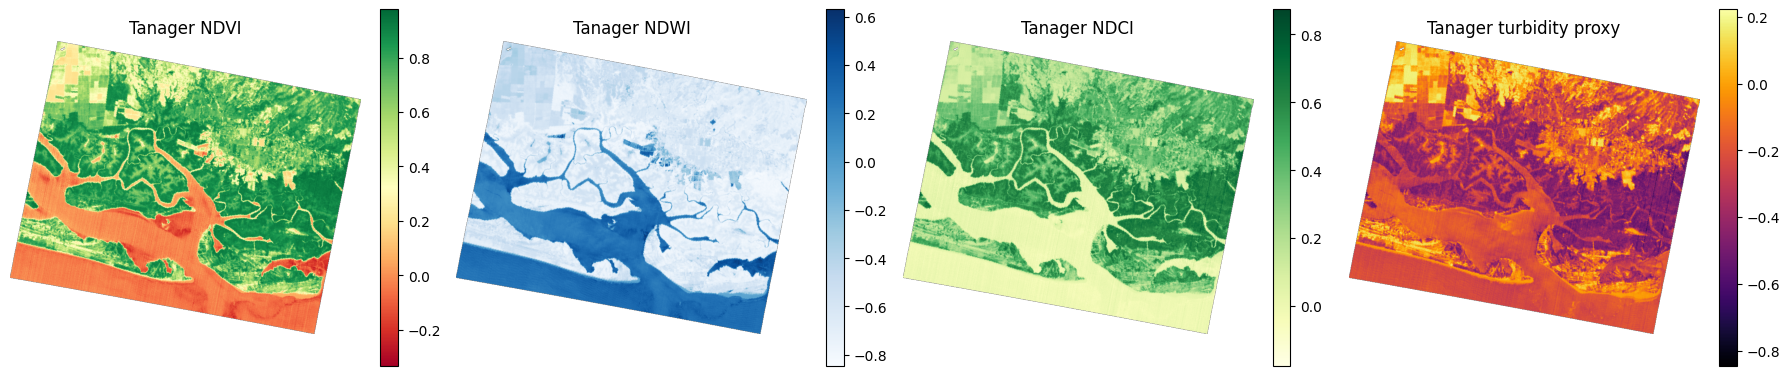

In [7]:
fig,ax=plt.subplots(1,4,figsize=(18,4))
for a,data,title,cmap in zip(ax,[NDVI_T,NDWI_T,NDCI_T,TURBIDITY_T],['Tanager NDVI','Tanager NDWI','Tanager NDCI','Tanager turbidity proxy'],['RdYlGn','Blues','YlGn','inferno']):
    im=a.imshow(data,cmap=cmap); a.set_title(title); a.axis('off'); fig.colorbar(im,ax=a,fraction=.046)
plt.tight_layout(); plt.show()


In [8]:

_tanager_vars=['R443','R560','R665','R708','R800','R860','NDVI_T','NDWI_T','NDCI_T','TURBIDITY_T','cloud','cirrus','nodata','valid','sr']
for _name in _tanager_vars:
    globals().pop(_name,None)
import gc
gc.collect()
print('Tanager arrays released; free memory before Sentinel-2 analysis.')


Tanager arrays released; free memory before Sentinel-2 analysis.


## Part B — Sentinel-2 mangrove change analysis

The Sentinel-2 workflow uses the same tile and shared grid for both dates, applies SCL cloud/shadow masking, and calculates statistics only inside the GMW 2020 mangrove mask.

In [9]:
GCC_SITES = {
    "United Arab Emirates": [
        54.2, 24.2, 54.8, 25.0
    ]
}

BASELINE_PERIOD = "2024-02-01/2024-03-10"
LATER_PERIOD = "2025-02-01/2025-03-10"
MAX_CLOUD_COVER = 30
OUTPUT_SIZE = 700

In [10]:

gmw_dir=Path('gmw_2020'); gmw_dir.mkdir(exist_ok=True)
gmw_files=list(gmw_dir.rglob('*.tif'))
if not gmw_files:
    rec=requests.get('https://zenodo.org/api/records/6894273',timeout=60).json()
    info=next(f for f in rec['files'] if f['key']=='gmw_v3_2020_gtiff.zip')
    data=requests.get(info['links']['self'],timeout=300).content
    with zipfile.ZipFile(io.BytesIO(data)) as z: z.extractall(gmw_dir)
    gmw_files=list(gmw_dir.rglob('*.tif'))
if not gmw_files: raise FileNotFoundError('No GMW GeoTIFF files found')
print('GMW files available:',len(gmw_files))


GMW files available: 1521


In [11]:


catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace
)

SENTINEL_COLLECTION = "sentinel-2-l2a"
BASELINE_ITEM_ID = "S2B_MSIL2A_20240222T064909_R020_T40RBN_20240222T114638"
LATER_ITEM_ID = "S2C_MSIL2A_20250204T070131_R063_T40RBN_20250204T101810"

collection = catalog.get_collection(SENTINEL_COLLECTION)
baseline_item = collection.get_item(BASELINE_ITEM_ID)
later_item = collection.get_item(LATER_ITEM_ID)

if baseline_item is None:
    raise RuntimeError(f"Could not load baseline scene: {BASELINE_ITEM_ID}")
if later_item is None:
    raise RuntimeError(f"Could not load later scene: {LATER_ITEM_ID}")

pairs = {
    "United Arab Emirates": {
        "tile": "40RBN",
        "baseline": baseline_item,
        "later": later_item,
    }
}

print("United Arab Emirates")
print("Tile:", pairs["United Arab Emirates"]["tile"])
print("Baseline:", baseline_item.datetime.date(), BASELINE_ITEM_ID)
print("Later:", later_item.datetime.date(), LATER_ITEM_ID)
print("Cloud cover:",
      baseline_item.properties.get("eo:cloud_cover"),
      later_item.properties.get("eo:cloud_cover"))


United Arab Emirates
Tile: 40RBN
Baseline: 2024-02-22 S2B_MSIL2A_20240222T064909_R020_T40RBN_20240222T114638
Later: 2025-02-04 S2C_MSIL2A_20250204T070131_R063_T40RBN_20250204T101810
Cloud cover: 0.352228 0.231268


**Reproducibility note:** This notebook uses two fixed Sentinel-2 Level-2A scenes from tile `40RBN` so that a fresh run does not repeatedly query the STAC catalog or trigger an API rate limit. The analysis remains a preliminary indicator and requires field verification.


In [12]:
def load_pair(pair, bbox):
    """
    Load Sentinel-2 green, red, and NIR bands on one shared grid.
    Calculates preliminary NDVI and NDWI indicators.
    """

    resolution = (bbox[2] - bbox[0]) / OUTPUT_SIZE

    cube = stackstac.stack(
        [
            pair["baseline"],
            pair["later"]
        ],
        assets=["B03", "B04", "B08"],
        bounds=bbox,
        epsg=4326,
        resolution=resolution,
        snap_bounds=False,
        fill_value=np.nan,
        resampling=Resampling.nearest
    ).compute().values

    green_baseline = cube[0, 0] / 10000.0
    red_baseline = cube[0, 1] / 10000.0
    nir_baseline = cube[0, 2] / 10000.0

    green_later = cube[1, 0] / 10000.0
    red_later = cube[1, 1] / 10000.0
    nir_later = cube[1, 2] / 10000.0

    with np.errstate(divide="ignore", invalid="ignore"):
        ndvi_baseline = (
            (nir_baseline - red_baseline)
            / (nir_baseline + red_baseline)
        )
        ndvi_later = (
            (nir_later - red_later)
            / (nir_later + red_later)
        )
        ndwi_baseline = (
            (nir_baseline - green_baseline)
            / (nir_baseline + green_baseline)
        )
        ndwi_later = (
            (nir_later - green_later)
            / (nir_later + green_later)
        )

    valid = (
        np.isfinite(ndvi_baseline)
        & np.isfinite(ndvi_later)
        & np.isfinite(ndwi_baseline)
        & np.isfinite(ndwi_later)
    )

    ndvi_baseline[~valid] = np.nan
    ndvi_later[~valid] = np.nan
    ndwi_baseline[~valid] = np.nan
    ndwi_later[~valid] = np.nan

    ndvi_change = ndvi_later - ndvi_baseline
    ndwi_change = ndwi_later - ndwi_baseline

    transform = from_bounds(
        *bbox,
        width=ndvi_baseline.shape[1],
        height=ndvi_baseline.shape[0]
    )

    print("Valid Sentinel pixels:", int(valid.sum()))

    return (
        ndvi_baseline,
        ndvi_later,
        ndvi_change,
        ndwi_baseline,
        ndwi_later,
        ndwi_change,
        transform,
        valid
    )


def _intersects(bounds, bbox):
    return not (
        bounds.right < bbox[0]
        or bounds.left > bbox[2]
        or bounds.top < bbox[1]
        or bounds.bottom > bbox[3]
    )


def gmw_on_grid(transform, shape, bbox):
    """
    Reproject intersecting GMW tiles onto the Sentinel-2 grid
    without overwriting previous tiles.
    """

    output = np.zeros(shape, dtype="uint8")
    used_tiles = 0

    for tif in gmw_files:
        with rasterio.open(str(tif)) as src:
            if not _intersects(src.bounds, bbox):
                continue

            tile_output = np.zeros(shape, dtype="uint8")

            reproject(
                source=rasterio.band(src, 1),
                destination=tile_output,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=transform,
                dst_crs="EPSG:4326",
                resampling=Resampling.nearest,
                src_nodata=0,
                dst_nodata=0
            )

            output = np.maximum(output, tile_output)
            used_tiles += 1

    print("GMW tiles used:", used_tiles)
    print("GMW pixels on Sentinel grid:", int(output.sum()))

    return output.astype(bool)


In [13]:
results = {}
arrays = {}

for country, pair in pairs.items():
    (
        ndvi_baseline,
        ndvi_later,
        ndvi_change,
        ndwi_baseline,
        ndwi_later,
        ndwi_change,
        transform,
        valid
    ) = load_pair(pair, GCC_SITES[country])

    mask = valid & gmw_on_grid(
        transform,
        ndvi_later.shape,
        GCC_SITES[country]
    )

    vb = ndvi_baseline[mask]
    vl = ndvi_later[mask]
    vd = ndvi_change[mask]

    wb = ndwi_baseline[mask]
    wl = ndwi_later[mask]
    wd = ndwi_change[mask]

    if not len(vd):
        continue

    results[country] = {
        "country": country,
        "tile": pair["tile"],
        "baseline_date": str(pair["baseline"].datetime.date()),
        "later_date": str(pair["later"].datetime.date()),
        "baseline_median_ndvi": float(np.median(vb)),
        "later_median_ndvi": float(np.median(vl)),
        "median_ndvi_change": float(np.median(vd)),
        "baseline_median_ndwi": float(np.median(wb)),
        "later_median_ndwi": float(np.median(wl)),
        "median_ndwi_change": float(np.median(wd)),
        "strong_decrease_percent": float(np.mean(vd < -0.10) * 100),
        "strong_increase_percent": float(np.mean(vd > 0.10) * 100),
        "valid_mangrove_pixels": int(len(vd)),
        "status": "Preliminary indicator — field verification required"
    }

    arrays[country] = (
        ndvi_baseline,
        ndvi_later,
        ndvi_change,
        ndwi_baseline,
        ndwi_later,
        ndwi_change,
        transform,
        mask
    )

summary = pd.DataFrame(results.values())
display(summary)


Valid Sentinel pixels: 418586
GMW tiles used: 1
GMW pixels on Sentinel grid: 6038


,country,tile,baseline_date,later_date,baseline_median_ndvi,later_median_ndvi,median_ndvi_change,baseline_median_ndwi,later_median_ndwi,median_ndwi_change,strong_decrease_percent,strong_increase_percent,valid_mangrove_pixels,status
0,United Arab Emirates,40RBN,2024-02-22,2025-02-04,0.293612,0.307086,0.006236,0.2565,0.287613,0.013482,1.960784,9.526452,5406,Preliminary indicator — field verification req...


In [14]:
from pathlib import Path

dashboard_dir = Path("images")
results_dir = Path("results")
dashboard_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

features = []

for country, (
    ndvi_baseline,
    ndvi_later,
    ndvi_change,
    ndwi_baseline,
    ndwi_later,
    ndwi_change,
    transform,
    mask
) in arrays.items():

    rows, cols = np.where(mask)
    step = max(1, int(np.ceil(len(rows) / 2000)))

    for row, col in zip(rows[::step], cols[::step]):
        longitude, latitude = rasterio.transform.xy(
            transform,
            int(row),
            int(col)
        )

        ndvi_delta = float(ndvi_change[row, col])
        ndwi_delta = float(ndwi_change[row, col])

        status = (
            "Possible decrease"
            if ndvi_delta < -0.10
            else "Possible increase"
            if ndvi_delta > 0.10
            else "Stable"
        )

        features.append({
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    float(longitude),
                    float(latitude)
                ]
            },
            "properties": {
                "country": country,
                "baseline_ndvi": round(
                    float(ndvi_baseline[row, col]),
                    4
                ),
                "later_ndvi": round(
                    float(ndvi_later[row, col]),
                    4
                ),
                "ndvi_change": round(ndvi_delta, 4),
                "ndwi_change": round(ndwi_delta, 4),
                "change_status": status,
                "recommended_action": (
                    "Field or UAV inspection recommended"
                    if status == "Possible decrease"
                    else "Continue monitoring"
                )
            }
        })

summary.to_csv(
    dashboard_dir / "gcc_mangrove_summary.csv",
    index=False
)

with open(
    dashboard_dir / "gcc_mangrove_analysis_points.geojson",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "type": "FeatureCollection",
            "features": features
        },
        file,
        indent=2
    )

with open(
    dashboard_dir / "analysis_metadata.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        {
            "reference_layer": "Global Mangrove Watch 2020",
            "monitoring_source": "Sentinel-2 L2A",
            "hyperspectral_source": "Planet Tanager",
            "comparison": (
                "2024-02-22 versus 2025-02-04, Sentinel-2 tile 40RBN"
            ),
            "qualification": (
                "Preliminary indicator; not a validated health "
                "classification; field verification required."
            )
        },
        file,
        indent=2
    )

uae_result = results.get("United Arab Emirates")

if uae_result:
    uae_summary = {
        "status": "Preliminary scene-level indicator",
        "baseline_date": uae_result["baseline_date"],
        "later_date": uae_result["later_date"],
        "common_tile": uae_result["tile"],
        "ndvi": {
            "baseline_median": uae_result["baseline_median_ndvi"],
            "later_median": uae_result["later_median_ndvi"],
            "scene_level_change": uae_result["median_ndvi_change"],
            "interpretation": (
                "Preliminary scene-level indicator"
            )
        },
        "ndwi": {
            "baseline_median": uae_result["baseline_median_ndwi"],
            "later_median": uae_result["later_median_ndwi"],
            "scene_level_change": uae_result["median_ndwi_change"],
            "interpretation": (
                "Preliminary scene-level indicator"
            )
        },
        "pixel_level_change_available": True,
        "notes": (
            "Values are calculated inside the Global Mangrove Watch "
            "2020 reference mask. Field validation is required."
        )
    }

    with open(
        dashboard_dir / "uae_indices_summary.json",
        "w",
        encoding="utf-8"
    ) as file:
        json.dump(uae_summary, file, indent=2)

if "fig" in globals():
    fig.savefig(
        results_dir / "example_output.png",
        dpi=150,
        bbox_inches="tight"
    )

print(
    "Exported",
    len(features),
    "dashboard points to",
    dashboard_dir
)


Exported 1802 dashboard points to images


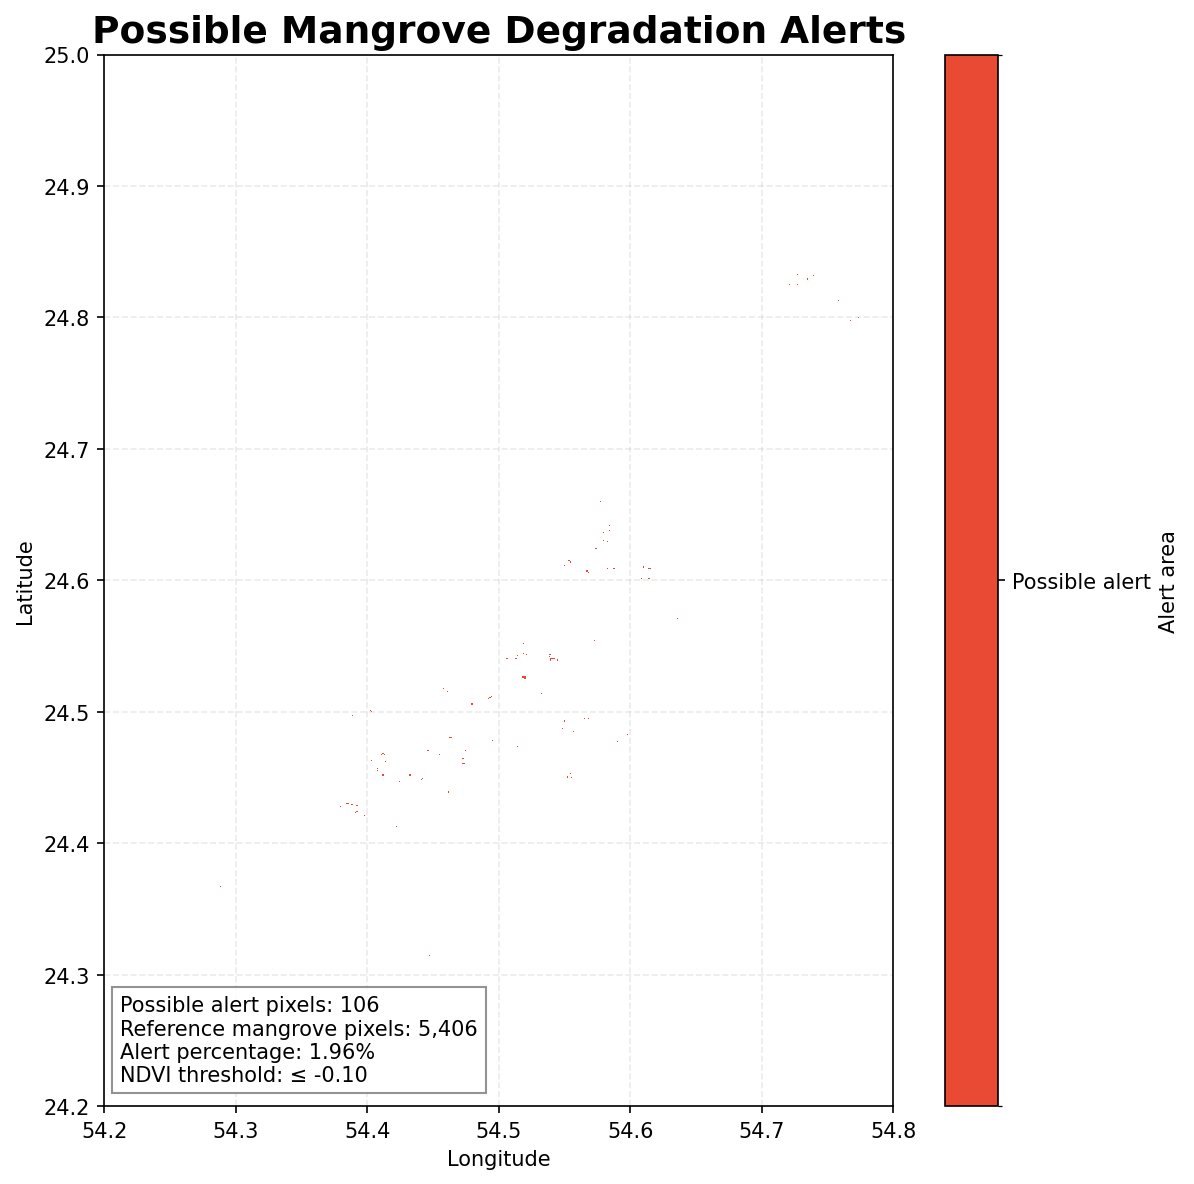

Saved possible alert map with 106 possible alert pixels.


In [15]:
# ---------------------------------------------------------
# Possible mangrove degradation alert map
# ---------------------------------------------------------

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from rasterio.transform import array_bounds

country = "United Arab Emirates"

(
    ndvi_baseline,
    ndvi_later,
    ndvi_change,
    ndwi_baseline,
    ndwi_later,
    ndwi_change,
    transform,
    mangrove_mask
) = arrays[country]

# Same threshold used for the dashboard points
STRESS_THRESHOLD = -0.10

possible_alerts = (
    mangrove_mask
    & np.isfinite(ndvi_change)
    & (ndvi_change <= STRESS_THRESHOLD)
)

alert_layer = np.where(possible_alerts, 1.0, np.nan)

height, width = ndvi_change.shape

west, south, east, north = array_bounds(
    height,
    width,
    transform
)

fig, ax = plt.subplots(
    figsize=(13, 8),
    dpi=150
)

ax.set_facecolor("white")

cmap = ListedColormap(["#e84a33"])
norm = BoundaryNorm(
    [0.5, 1.5],
    cmap.N
)

image = ax.imshow(
    alert_layer,
    extent=[west, east, south, north],
    origin="upper",
    cmap=cmap,
    norm=norm,
    interpolation="nearest"
)

colorbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.035,
    pad=0.03
)

colorbar.set_ticks([1])
colorbar.set_ticklabels(["Possible alert"])
colorbar.set_label("Alert area")

ax.set_title(
    "Possible Mangrove Degradation Alerts",
    fontsize=18,
    fontweight="bold"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

ax.grid(
    True,
    alpha=0.25,
    linestyle="--"
)

alert_count = int(np.sum(possible_alerts))
mangrove_count = int(np.sum(mangrove_mask))

alert_percentage = (
    100 * alert_count / mangrove_count
    if mangrove_count > 0
    else 0
)

ax.text(
    0.02,
    0.02,
    (
        f"Possible alert pixels: {alert_count:,}\n"
        f"Reference mangrove pixels: {mangrove_count:,}\n"
        f"Alert percentage: {alert_percentage:.2f}%\n"
        f"NDVI threshold: ≤ {STRESS_THRESHOLD:.2f}"
    ),
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="bottom",
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.85
    )
)

plt.tight_layout()

# Save in both required locations
Path("results").mkdir(exist_ok=True)
Path("images").mkdir(exist_ok=True)

fig.savefig(
    "results/possible_mangrove_degradation_alerts.png",
    dpi=150,
    bbox_inches="tight"
)

fig.savefig(
    "images/possible_mangrove_degradation_alerts.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print(
    f"Saved possible alert map with {alert_count:,} possible alert pixels."
)

## Interpretation and limitations

Tanager indices are exploratory spectral proxies. Sentinel-2 NDVI change is a possible stress signal only when observed inside the GMW 2020 reference mask. Results can be affected by tides, seasonality, atmospheric conditions, residual cloud/shadow, and the reference-layer date. Validate with field observations, UAV imagery, or known disturbance events before making ecological or carbon claims.